# 08 — Variáveis Aleatórias Contínuas

No notebook 07, as variáveis assumiam valores "contáveis" (0, 1, 2, ...). Mas a altura de uma pessoa, o peso de um pinguim ou o tempo até o próximo cliente podem assumir **qualquer valor** num intervalo: 1,73 m, 1,7312 m, 1,731245 m... São as variáveis **contínuas**.

Neste notebook vamos:
- Entender por que $P(X = x) = 0$ para uma variável contínua e o que é a **função densidade (PDF)**
- Calcular probabilidades como **áreas**, usando a **função de distribuição acumulada (CDF)**
- Conhecer a distribuição **uniforme**, a **normal** e a **exponencial** (e, rapidamente, a log-normal)
- Padronizar valores com o **z-score**
- Verificar se dados seguem uma distribuição com o **Q-Q plot**
- **Ajustar** uma distribuição a dados reais

## 1. Importando bibliotecas e carregando os dados

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

pd.set_option("display.precision", 4)
plt.rcParams["figure.dpi"] = 100
rng = np.random.default_rng(42)

gorjetas = sns.load_dataset("tips")
pinguins = sns.load_dataset("penguins").dropna()

## 🎓 Conceito: densidade de probabilidade

Qual a probabilidade de um pinguim pesar **exatamente** 3.700,000000... gramas? Com infinitas casas decimais possíveis, a resposta é **zero**. Para variáveis contínuas, só faz sentido perguntar sobre **intervalos**: qual a chance de pesar entre 3.600 e 3.800 g?

A **função densidade de probabilidade** (PDF, $f(x)$) é a versão contínua da PMF. Ela é o limite de um histograma com `density=True` quando temos infinitos dados e faixas infinitamente estreitas. As regras:
- $f(x) \ge 0$, e a **área total** sob a curva é 1.
- A probabilidade de um intervalo é a **área sob a curva** nesse intervalo:
$$P(a \le X \le b) = \int_a^b f(x)\,dx$$
  (O símbolo $\int$, a **integral**, é a "soma contínua" das áreas. Não vamos calcular integrais à mão: o computador faz isso por nós.)
- **Atenção:** $f(x)$ **não** é uma probabilidade e pode até ser maior que 1. Só a área é probabilidade.

A **função de distribuição acumulada** (CDF), $F(x) = P(X \le x)$, é a área acumulada da esquerda até $x$. É a versão teórica da **ECDF** do notebook 03. Com ela, $P(a \le X \le b) = F(b) - F(a)$, sem precisar de integrais.

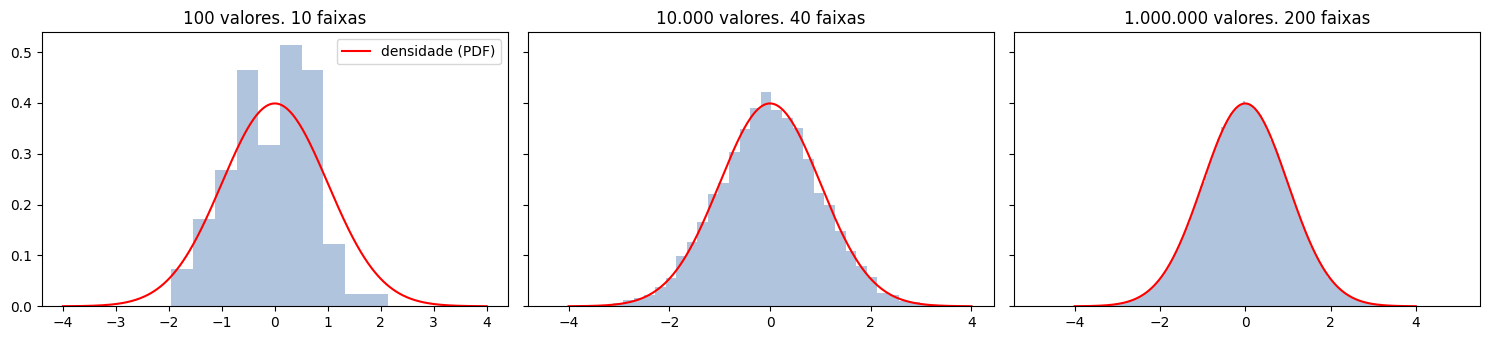

In [2]:
# Histogramas de amostras cada vez maiores, com faixas cada vez mais estreitas, convergindo para a densidade.
fig, axes = plt.subplots(1, 3, figsize=(15, 3.5), sharey=True)
eixo = np.linspace(-4, 4, 400)
for ax, (n, bins) in zip(axes, [(100, 10), (10_000, 40), (1_000_000, 200)]):
    ax.hist(rng.normal(size=n), bins=bins, density=True, color="lightsteelblue")
    ax.plot(eixo, stats.norm.pdf(eixo), color="red", label="densidade (PDF)")
    ax.set_title(f"{n:,} valores, {bins} faixas".replace(",", "."))
axes[0].legend()
plt.tight_layout()
plt.show()

In [3]:
# Probabilidade como área: P(-1 ≤ X ≤ 1) para a normal padrão, de três jeitos.
normal = stats.norm(0, 1)

# 1) Somando a área de muitos retângulos finíssimos (uma integral "à mão").
x = np.linspace(-1, 1, 100_001)
largura = x[1] - x[0]
area_retangulos = np.sum(normal.pdf(x[:-1]) * largura)   # x[:-1] = todos menos o último

# 2) Pela CDF: F(1) - F(-1).
area_cdf = normal.cdf(1) - normal.cdf(-1)

# 3) Por simulação: a proporção de valores sorteados que caem no intervalo.
amostra = normal.rvs(size=1_000_000, random_state=rng)   # .rvs sorteia valores da distribuição
area_sim = np.mean((amostra >= -1) & (amostra <= 1))

print(f"Retângulos: {area_retangulos:.4f}   CDF: {area_cdf:.4f}   Simulação: {area_sim:.4f}")
print(f"P(X = 0 exatamente) na simulação: {np.mean(amostra == 0)}")
print(f"Densidade no pico, f(0) = {normal.pdf(0):.4f}; com desvio 0,1, f(0) = {stats.norm(0, 0.1).pdf(0):.4f} (maior que 1!)")

Retângulos: 0.6827   CDF: 0.6827   Simulação: 0.6831
P(X = 0 exatamente) na simulação: 0.0
Densidade no pico, f(0) = 0.3989; com desvio 0,1, f(0) = 3.9894 (maior que 1!)


**Conclusão:** nos histogramas, com 100 valores e 10 faixas o desenho é grosseiro; com 1 milhão de valores e 200 faixas, ele coincide com a curva vermelha. A densidade é o **"histograma ideal"**.

As três formas de calcular $P(-1 \le X \le 1)$ concordam: somando retângulos (**0,6827**), pela CDF (**0,6827**) e por simulação (0,6831). Entre 1 milhão de valores sorteados, **nenhum** foi exatamente 0: um valor isolado tem probabilidade zero. E a densidade de uma normal estreita (desvio 0,1) chega a **3,99** no pico, mostrando que a densidade não é uma probabilidade; o que nunca passa de 1 é a **área**.

## 🎓 Conceito: distribuição uniforme

A **uniforme** no intervalo $[a, b]$ é a mais simples das contínuas: todos os valores do intervalo são "igualmente prováveis", e a densidade é um **retângulo** de altura $1/(b - a)$ (para que a área seja 1).
- $E[X] = (a + b)/2$ e $\text{Var}(X) = (b - a)^2/12$.
- É ela que o computador sorteia em `rng.random()` (uniforme entre 0 e 1), e todas as outras distribuições podem ser construídas a partir dela.

🔗 **Ponte para o ML:** o `RandomizedSearchCV` do ML-01 sorteava hiperparâmetros de distribuições como a uniforme e a log-uniforme.

In [4]:
espera = stats.uniform(loc=0, scale=10)   # no scipy: uniforme de loc até loc + scale, ou seja, [0, 10]
print("Um ônibus passa a cada 10 minutos, e você chega num momento aleatório:")
print(f"  Espera média: {espera.mean():.1f} min   desvio padrão: {espera.std():.2f} min (= 10/√12)")
print(f"  P(esperar mais de 7 minutos) = {espera.sf(7):.2f}")
print(f"  P(esperar entre 2 e 5 minutos) = {espera.cdf(5) - espera.cdf(2):.2f}")

Um ônibus passa a cada 10 minutos, e você chega num momento aleatório:
  Espera média: 5.0 min   desvio padrão: 2.89 min (= 10/√12)
  P(esperar mais de 7 minutos) = 0.30
  P(esperar entre 2 e 5 minutos) = 0.30


## 🎓 Conceito: distribuição normal

A **normal** (ou gaussiana, a "curva em sino") é a distribuição mais importante da estatística. Ela tem dois parâmetros: a média $\mu$ (o centro) e o desvio padrão $\sigma$ (a largura). Escrevemos $X \sim N(\mu, \sigma^2)$, e a densidade é:

$$f(x) = \frac{1}{\sigma\sqrt{2\pi}}\, e^{-\frac{(x-\mu)^2}{2\sigma^2}}$$

Não é preciso decorar a fórmula. O importante:
- É **simétrica** em torno de $\mu$ (média = mediana = moda).
- A **regra 68–95–99,7:** cerca de 68% dos valores ficam a até 1 desvio padrão da média, 95% a até 2, e 99,7% a até 3.
- Somas e médias de muitas variáveis independentes tendem a ser normais, **qualquer que seja** a distribuição original. É o **Teorema Central do Limite** (notebook 10), e é por isso que ela aparece em tantos lugares.

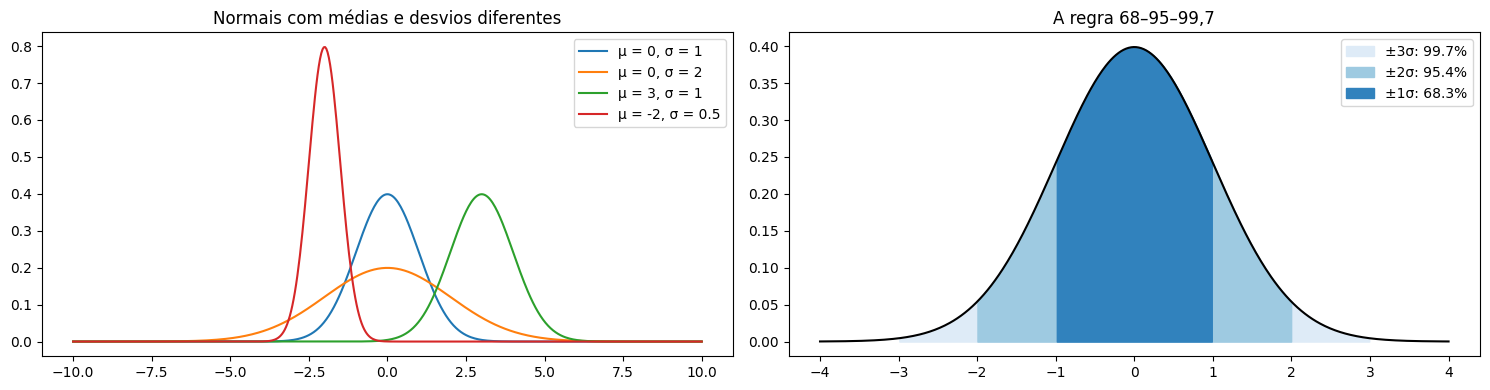

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(15, 4))
eixo = np.linspace(-10, 10, 500)
for mu, sigma in [(0, 1), (0, 2), (3, 1), (-2, 0.5)]:
    axes[0].plot(eixo, stats.norm.pdf(eixo, mu, sigma), label=f"μ = {mu}, σ = {sigma}")
axes[0].set_title("Normais com médias e desvios diferentes")
axes[0].legend()

# A regra 68-95-99,7, pintando as áreas.
eixo = np.linspace(-4, 4, 500)
axes[1].plot(eixo, stats.norm.pdf(eixo), color="black")
for k, cor in [(3, "#deebf7"), (2, "#9ecae1"), (1, "#3182bd")]:
    faixa = (eixo >= -k) & (eixo <= k)
    area = stats.norm.cdf(k) - stats.norm.cdf(-k)
    axes[1].fill_between(eixo[faixa], stats.norm.pdf(eixo[faixa]), color=cor, label=f"±{k}σ: {area:.1%}")
axes[1].set_title("A regra 68–95–99,7")
axes[1].legend()
plt.tight_layout()
plt.show()

**Conclusão:** à esquerda, $\mu$ **desloca** a curva (a verde, com $\mu = 3$, é a azul empurrada para a direita) e $\sigma$ muda a **largura**: com $\sigma = 2$ (laranja) a curva fica achatada e baixa; com $\sigma = 0{,}5$ (vermelha) fica estreita e alta. A área é sempre 1, então quanto mais estreita, mais alta.

À direita, as áreas calculadas pela CDF confirmam a regra: **68,3%** a até 1 desvio, **95,4%** a até 2 e **99,7%** a até 3. Valores a mais de 3 desvios da média são raríssimos numa normal (0,3%). Por isso, "mais de 3 desvios padrão" é uma regra comum para suspeitar de outliers quando os dados são aproximadamente normais.

## 🎓 Conceito: z-score (padronização)

O **z-score** de um valor diz **a quantos desvios padrão ele está da média**:

$$z = \frac{x - \mu}{\sigma}$$

- $z = 0$: o valor está exatamente na média; $z = 2$: está 2 desvios acima; $z = -1{,}5$: 1,5 desvio abaixo.
- Se $X$ é normal, $Z$ é a **normal padrão** $N(0, 1)$. Assim, qualquer pergunta sobre uma normal vira uma pergunta sobre a normal padrão.
- O z-score permite **comparar** valores de escalas diferentes: um pinguim pesado e uma nadadeira longa podem ser comparados em "desvios padrão".

🔗 **Ponte para o ML:** o `StandardScaler` do ML-01 e do ML-02 calcula exatamente o z-score de cada coluna (com a média e o desvio do treino), para que todas fiquem na mesma escala.

In [6]:
# Os pinguins Adelie: massa corporal e comprimento da nadadeira.
adelie = pinguins[pinguins["species"] == "Adelie"]
massa = adelie["body_mass_g"]
nadadeira = adelie["flipper_length_mm"]

# Um pinguim específico: o mais pesado dos Adelie.
indice = massa.idxmax()                    # idxmax devolve o RÓTULO da linha com o maior valor
z_massa = (massa[indice] - massa.mean()) / massa.std()
z_nadadeira = (nadadeira[indice] - nadadeira.mean()) / nadadeira.std()
print(f"O Adelie mais pesado: {massa[indice]:.0f} g (z = {z_massa:.2f}) e nadadeira de {nadadeira[indice]:.0f} mm (z = {z_nadadeira:.2f})")

# Padronizando a coluna inteira: o resultado tem média 0 e desvio 1.
z = (massa - massa.mean()) / massa.std()
print(f"Massa padronizada: média = {z.mean():.4f}, desvio = {z.std():.4f}")

# Se a massa for normal, que fração dos Adelie deveria pesar mais de 4.500 g? E qual a fração real?
mu, sigma = massa.mean(), massa.std()
print(f"\nNormal(μ = {mu:.0f}, σ = {sigma:.0f}): P(massa > 4500) = {stats.norm(mu, sigma).sf(4500):.3f}")
print(f"Proporção real nos dados:                {np.mean(massa > 4500):.3f}")

O Adelie mais pesado: 4775 g (z = 2.33) e nadadeira de 197 mm (z = 1.06)
Massa padronizada: média = 0.0000, desvio = 1.0000

Normal(μ = 3706, σ = 459): P(massa > 4500) = 0.042
Proporção real nos dados:                0.048


**Conclusão:** o Adelie mais pesado tem **4.775 g**, um z-score de **2,33**: está bem acima do típico da espécie. Já a nadadeira dele (197 mm, z = **1,06**) é só um pouco maior que a média. O z-score permitiu comparar gramas com milímetros. Depois da padronização, a coluna tem média **0** e desvio **1**, como o `StandardScaler` faria.

Supondo que a massa dos Adelie é normal (com $\mu = 3.706$ g e $\sigma = 459$ g), a probabilidade de passar de 4.500 g seria **4,2%**; a proporção real é **4,8%**. O modelo normal descreve bem essa variável. Vamos confirmar isso com o Q-Q plot logo abaixo.

## 🎓 Conceito: distribuição exponencial

A **exponencial** descreve o **tempo de espera** entre eventos que acontecem a uma taxa constante $\lambda$, ou seja, o tempo entre as chegadas de um processo de **Poisson** (notebook 07):

$$f(x) = \lambda e^{-\lambda x}, \quad x \ge 0 \qquad E[X] = 1/\lambda$$

Se chegam em média 4 clientes por hora, o tempo médio entre dois clientes é 1/4 de hora (15 minutos). Assim como a geométrica, a exponencial **não tem memória**: ter esperado 20 minutos não torna a próxima chegada mais iminente. Ela é a "geométrica contínua".

Tempo médio entre clientes: 15.0 min (teoria: 15 min)


Clientes por hora: média 3.991, variância 3.993   ← Poisson(4)!
P(esperar mais de 30 min) = 0.1353


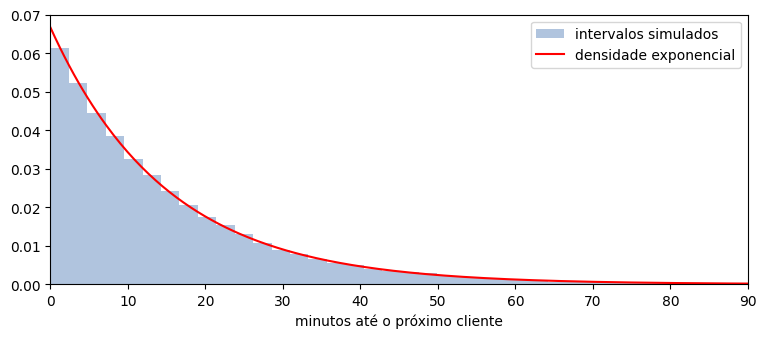

In [7]:
lam = 4   # clientes por hora
exponencial = stats.expon(scale=1 / lam)   # o scipy usa scale = 1/λ

# Simulando um dia de chegadas: intervalos exponenciais somados (np.cumsum) dão os horários de chegada.
intervalos = exponencial.rvs(size=100_000, random_state=rng)
horarios = np.cumsum(intervalos)
# Quantos clientes em cada hora cheia? np.floor arredonda para baixo (3,7 h → hora 3), e np.bincount conta
# quantas vezes cada hora aparece, incluindo as horas SEM nenhum cliente (contagem 0).
# [:-1] descarta a última hora, que ficou incompleta.
por_hora = np.bincount(np.floor(horarios).astype(int))[:-1]
print(f"Tempo médio entre clientes: {intervalos.mean() * 60:.1f} min (teoria: {60 / lam:.0f} min)")
print(f"Clientes por hora: média {por_hora.mean():.3f}, variância {por_hora.var():.3f}   ← Poisson(4)!")
print(f"P(esperar mais de 30 min) = {exponencial.sf(0.5):.4f}")

fig, ax = plt.subplots(figsize=(9, 3.5))
ax.hist(intervalos * 60, bins=80, density=True, color="lightsteelblue", label="intervalos simulados")
eixo = np.linspace(0, 90, 300)
ax.plot(eixo, exponencial.pdf(eixo / 60) / 60, color="red", label="densidade exponencial")   # /60: de horas para minutos
ax.set_xlabel("minutos até o próximo cliente")
ax.set_xlim(0, 90)
ax.legend()
plt.show()

**Conclusão:** a simulação reproduz a teoria: o tempo médio entre clientes é **15,0 minutos**, e a chance de esperar mais de meia hora é **13,5%**. O histograma dos intervalos acompanha a curva exponencial: esperas curtas são as mais comuns, mas de vez em quando passa mais de uma hora sem ninguém.

O resultado mais bonito está na contagem por hora: gerando os clientes com intervalos **exponenciais**, o número de clientes em cada hora teve média **3,991** e variância **3,993**, exatamente a assinatura da **Poisson(4)** do notebook 07. Exponencial e Poisson são duas faces do mesmo fenômeno: uma mede **quanto tempo** entre eventos, a outra **quantos eventos** num intervalo.

## 🎓 Conceito: Q-Q plot

Como saber se os dados seguem uma distribuição normal (ou qualquer outra)? O histograma ajuda, mas engana com poucos dados. O **Q-Q plot** (gráfico quantil-quantil) é mais preciso:
- No eixo x, os **quantis teóricos** da distribuição (por exemplo, da normal).
- No eixo y, os **quantis observados** nos dados (os valores ordenados).

Se os dados seguem a distribuição, os pontos ficam **sobre uma reta**. Os desvios da reta têm significado:
- Pontos que **sobem** na ponta direita: cauda direita mais longa que a da normal (assimetria à direita).
- Forma de **"S"**: caudas mais pesadas (ou mais leves) que a normal.

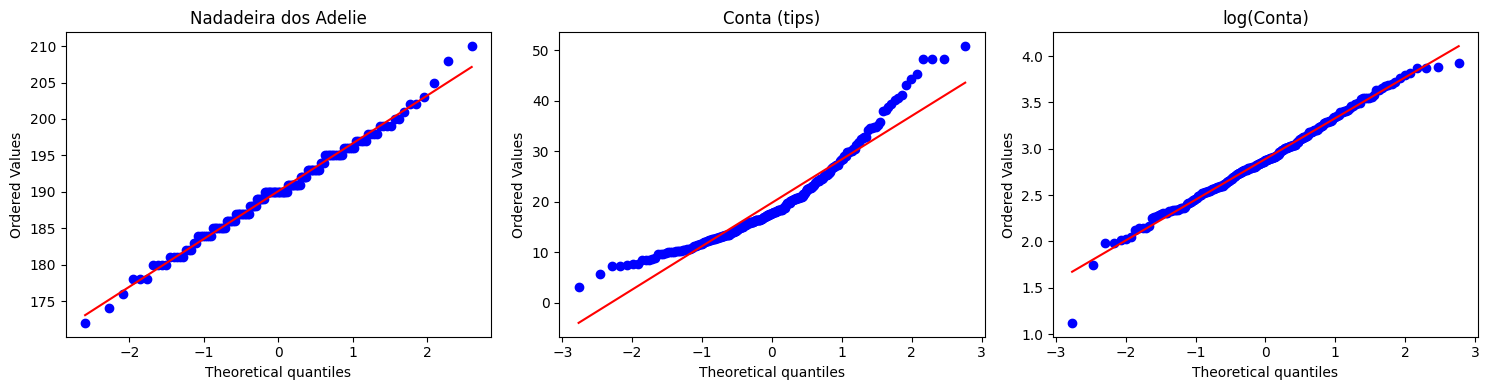

In [8]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
# stats.probplot faz o Q-Q plot contra a normal; plot=ax desenha no eixo indicado.
stats.probplot(adelie["flipper_length_mm"], dist="norm", plot=axes[0])
axes[0].set_title("Nadadeira dos Adelie")
stats.probplot(gorjetas["total_bill"], dist="norm", plot=axes[1])
axes[1].set_title("Conta (tips)")
stats.probplot(np.log(gorjetas["total_bill"]), dist="norm", plot=axes[2])
axes[2].set_title("log(Conta)")
plt.tight_layout()
plt.show()

**Conclusão:** - **Nadadeira dos Adelie:** os pontos seguem a reta vermelha de ponta a ponta. A variável é bem descrita por uma normal. (Os "degraus" aparecem porque as medidas foram arredondadas para milímetros inteiros.)
- **Conta (tips):** os pontos formam uma **curva**: na ponta esquerda ficam **acima** da reta (as contas pequenas não são tão pequenas quanto a normal preveria) e na direita sobem bem **acima** dela (as contas grandes são maiores que o previsto). É a assinatura da **assimetria à direita**.
- **log(Conta):** depois do log, os pontos voltam para a reta, com exceção de um ponto isolado embaixo à esquerda (a conta de US\$ 3,07). O log deixou a distribuição quase normal, confirmando o que vimos no notebook 03.

## 2. Ajustando uma distribuição aos dados

"Ajustar" uma distribuição é escolher os parâmetros que a deixam **mais parecida** com os dados. O método `.fit` do scipy usa a **máxima verossimilhança** (notebook 13). Para a normal, o resultado é simplesmente a média e o desvio padrão da amostra.

Vamos ajustar uma normal e uma **log-normal** às contas do tips. Uma variável é **log-normal** quando o seu **logaritmo** é normal: ela é sempre positiva e assimétrica à direita, um bom modelo para valores monetários (como a renda simulada do notebook 03).

Normal:     μ = 19.79, σ = 8.88
Log-normal: média do log = 2.890, desvio do log = 0.438
            (conferindo: média e desvio de log(conta) = 2.890, 0.438)


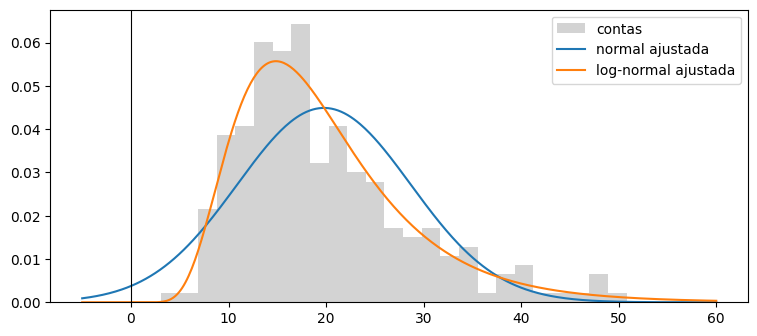

P(conta < 0):   normal = 0.0130   log-normal = 0.0000   real = 0
P(conta > 40):  normal = 0.0114   log-normal = 0.0341   real = 0.0410


In [9]:
contas = gorjetas["total_bill"].to_numpy()

mu, sigma = stats.norm.fit(contas)
# floc=0 fixa o "deslocamento" da log-normal em zero; s é o desvio do log e scale = e^(média do log).
s, loc, escala = stats.lognorm.fit(contas, floc=0)
print(f"Normal:     μ = {mu:.2f}, σ = {sigma:.2f}")
print(f"Log-normal: média do log = {np.log(escala):.3f}, desvio do log = {s:.3f}")
print(f"            (conferindo: média e desvio de log(conta) = {np.log(contas).mean():.3f}, {np.log(contas).std():.3f})")

fig, ax = plt.subplots(figsize=(9, 3.8))
ax.hist(contas, bins=25, density=True, color="lightgray", label="contas")
eixo = np.linspace(-5, 60, 400)
ax.plot(eixo, stats.norm.pdf(eixo, mu, sigma), label="normal ajustada")
ax.plot(eixo, stats.lognorm.pdf(eixo, s, loc, escala), label="log-normal ajustada")
ax.axvline(0, color="black", linewidth=0.8)
ax.legend()
plt.show()

# Que probabilidade cada modelo dá para algo impossível (uma conta negativa) e para contas altas?
print(f"P(conta < 0):   normal = {stats.norm.cdf(0, mu, sigma):.4f}   log-normal = {stats.lognorm.cdf(0, s, loc, escala):.4f}   real = 0")
print(f"P(conta > 40):  normal = {stats.norm.sf(40, mu, sigma):.4f}   log-normal = {stats.lognorm.sf(40, s, loc, escala):.4f}   real = {np.mean(contas > 40):.4f}")

**Conclusão:** a normal ajustada tem $\mu = 19{,}79$ e $\sigma = 8{,}88$ (o `.fit` divide por $n$, e não por $n-1$, por isso o desvio é um pouquinho menor que o 8,90 do notebook 02). Os parâmetros da log-normal são exatamente a média e o desvio de log(conta): **2,890** e **0,438**.

O gráfico e as probabilidades mostram que a **log-normal descreve muito melhor** as contas:
- A normal coloca o pico no lugar errado (perto de 20, quando as contas se concentram perto de 15) e prevê **1,3%** de contas **negativas**, um absurdo. A log-normal dá probabilidade zero para elas.
- Para contas acima de US\$ 40, a normal prevê só **1,1%**, mas a realidade é **4,1%**; a log-normal chega bem mais perto (**3,4%**), porque tem uma cauda direita longa.

Escolher a distribuição certa importa: um modelo baseado na normal **subestimaria** bastante a frequência de contas altas.

## 3. Resumo e próximos passos

| Distribuição | Uso típico | Parâmetros | $E[X]$ | `scipy.stats` |
|---|---|---|---|---|
| Uniforme | "qualquer valor do intervalo" | $a, b$ | $(a+b)/2$ | `uniform(loc=a, scale=b-a)` |
| Normal | medidas, erros, somas e médias | $\mu, \sigma$ | $\mu$ | `norm(mu, sigma)` |
| Exponencial | tempos de espera | $\lambda$ | $1/\lambda$ | `expon(scale=1/lam)` |
| Log-normal | valores positivos assimétricos (preços, rendas) | $\mu, \sigma$ do log | $e^{\mu + \sigma^2/2}$ | `lognorm(s=sigma, scale=e^mu)` |

Para as contínuas, `.pdf(x)` é a densidade (não uma probabilidade!), e as probabilidades saem da `.cdf` e da `.sf`.

**Conceitos que você aprendeu**
- Por que $P(X = x) = 0$ para contínuas, a **densidade (PDF)** e a probabilidade como **área**.
- A **CDF** e o cálculo de $P(a \le X \le b) = F(b) - F(a)$.
- As distribuições **uniforme**, **normal** (e a regra 68–95–99,7), **exponencial** e **log-normal**.
- O **z-score** e a padronização (o `StandardScaler`).
- O **Q-Q plot** para verificar uma distribuição, e o **ajuste** de distribuições com `.fit`.

**Python novo:** `stats.norm` / `uniform` / `expon` / `lognorm` e os métodos `.pdf`, `.rvs`, `.fit`; `fill_between`, `.idxmax()`, `np.floor`, `stats.probplot`, fatiamento `x[:-1]`.

**Próximo notebook:** até aqui, cada variável aleatória viveu sozinha. No notebook 09 vamos estudar **várias variáveis ao mesmo tempo**: distribuições **conjuntas**, **marginais** e **condicionais**, a **normal multivariada** e a **matriz de covariância**, que está por trás do PCA e de vários modelos de ML.